<center><h1> Test ESNGrad <h1><center>

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import torch 
import pandas as pd 
import numpy as np

# 1. Forecasting the RV

We try a simple forecast of the RV as in the paper. 

In [3]:
filename = 'data/SP500_RV_5min.xlsx'
raw = pd.read_excel(filename)
raw['Date'] = pd.to_datetime(raw['Date'], format='%Y%m%d')
RV = raw['RV']
print(RV.describe())
RV = torch.tensor(raw['RV'].to_numpy(), dtype=torch.float32).reshape(-1, 1)
len_train = 2000
RV_train = RV[:len_train].clone()
RV_test = RV[len_train:].clone()

count    4096.000000
mean        1.175221
std         2.315118
min         0.043289
25%         0.322543
50%         0.629452
75%         1.177538
max        60.562509
Name: RV, dtype: float64


## 1.1. Training

First we need to define our diffusion process. We use the standard `DDPM`. 

In [4]:
from rcdiff.diff import DDPM, BaseScheduler

K = 100

scheduler = BaseScheduler(K = K)
ddpm = DDPM(scheduler=scheduler)

Second, we need to define the encoder network. We use the `ESN` module and sample the parameters: 

In [5]:
from rcdiff import ESN 
from rcdiff import RandomWeight, ParametersESN

R = 50 
T, N = RV_train.shape

A = RandomWeight(dist="normal", sparsity=0.2, norm_type="spectral_radius")
C = RandomWeight(dist="uniform", sparsity=0.2, norm_type="l2")
zeta = RandomWeight(dist="uniform", sparsity=0.2, norm_type="euclidean")

esnParams = ParametersESN(A_RW = A, 
                 C_RW = C,
                 zeta_RW = zeta,
                 leak_rate = 0.2, 
                 rho = 0.1, 
                 gamma = 0.4,
                 omega = 0) 

esn = ESN(in_dim = N, 
          reservoir_size= R, 
          params=esnParams
          )

Then we need to define the denoiser network. Here we use the `SimpleMLP` network

In [6]:
from rcdiff.models.denoisers import SimpleMLP 

denoiser = SimpleMLP(in_dim=N,cond_dim=R, dim_hids=[32,64,32],time_dim=128)

Here we then define the training characteristics of the network: 

In [7]:
from rcdiff.models.config import TrainConfig

train_spec = TrainConfig(t0 = 100,                            
    batch_size = 64,
    lr = 1e-3,
    max_iters = 500,
    val_fraction = 0.1, 
    eval_every = 1,
    patience = 100,  
    ema_decay = 1,  
    grad_clip = 1.0,
    seed = 1234,
    device = "cpu")

In [8]:
from rcdiff.models.rcdiffusor import ESNGrad


esnGrad = ESNGrad(diff = ddpm, esn = esn, denoiser = denoiser, spec = train_spec)
loss, time = esnGrad.fit(x = RV_train, c = None)

Early stopping at iteration 244 | best val loss 0.1068


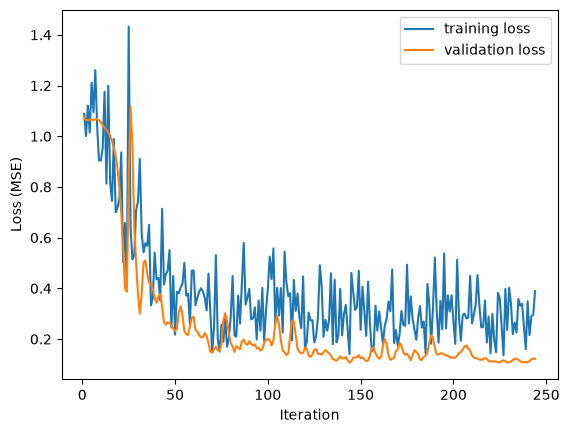

In [9]:
import matplotlib.pyplot as plt 

loss = pd.DataFrame(loss)
plt.plot(loss['iter'], loss['train'], label = 'training loss')
plt.plot(loss['iter'], loss['val'], label = 'validation loss')
plt.ylabel('Loss (MSE)')
plt.xlabel('Iteration')
plt.legend()
plt.show()

## 1.2. Test

In [13]:
x_hat, process_history = esnGrad.conditional_distribution(x = RV, c = None, n_samples=1000)

In [15]:
print(RV_test[0])
print(x_hat.mean(axis = 0))

tensor([0.6725])
tensor([0.5657])


In [ ]:
forecast = esnGrad.one_step_ahead_forecast(x_train = RV_train, 
                                           x_test = RV_test,
                                           n_samples = 100)

# Multivariate example with VAR

In [12]:
from rcdiff.data.var import VAR

Phi_1 = np.array([[0.5,0.1,0], [0,.1,.2],[0,.3,.3]]).T
Phi_2 = np.array([[0.25,0.06,0.02], [0,.07,8e-2],[0,.12,.15]]).T
Phi_3 = np.array([[0.125,0.037,0.018], [0,.031,.038],[0,.057,.069]]).T
sigma_u = np.array([[1.0, 0.3, 0.1],
                    [0.3, 1.0, 0.2],
                    [0.1, 0.2, 1.0]])
A = [Phi_1, Phi_2, Phi_3]

var = VAR(A_coefs=A, sigma_u=sigma_u)
y = var.generate_trajectory(T = 1000, batch_size=1, burn_in=50)
y = y.squeeze(0)
print(y.shape) 
print(y)

torch.Size([1000, 3])
tensor([[ 0.4367, -0.2716,  0.4833],
        [-0.5561, -1.2001, -0.0352],
        [ 0.4464, -1.2994, -0.8928],
        ...,
        [-2.3647,  0.2285,  1.6384],
        [-1.7534,  1.5079,  1.0832],
        [-1.7216,  0.1179,  0.9037]])


In [13]:
from rcdiff import ESN 
from rcdiff import RandomWeight, ParametersESN

R = 50 
T, N = y.shape
A = RandomWeight(dist="normal", sparsity=0.2,norm_type="spectral_radius")
C = RandomWeight(dist="uniform", sparsity=0.2,norm_type="l2")
zeta = RandomWeight(dist="uniform", sparsity=0.2,norm_type="euclidean")

esnParams = ParametersESN(A_RW = A, 
                 C_RW = C,
                 zeta_RW = zeta,
                 leak_rate = 0.2, 
                 rho = 0.1, 
                 gamma = 0.4,
                 omega = 0) 

esn = ESN(in_dim = N, 
          reservoir_size= R, 
          params=esnParams
          )

In [14]:
esn

ESN()